# Appendix D | Worked solutions

*Complexity and Memory Accounting*

Count arithmetic, live tensor payload, reserved capacity, and elapsed time separately. The worked examples show exactly which dimensions enter each estimate and why a smaller cache does not imply an identical speed improvement.

Eight exercises progress from tracing small calculations to diagnosing implementation errors. These are controlled numerical examples, not performance or model-quality benchmarks.

## Setup

Run all cells in order from anywhere inside the companion repository. The written PDF contains every problem, explanation, and plot; the notebook PDF adds the code and saved outputs. NumPy and Matplotlib are required; Appendix C also uses PyTorch. No downloads, credentials, GPU, or trained checkpoint are needed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/ch04_attention/attention.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})


## 1. Count permitted work

**Problem.** For six causal tokens, window width three including the current token, two query heads, and key/value widths four each, count permitted pairs and the MACs for the two attention products when excluded pairs are skipped.

**Solution.** Each query reads $\min(t,3)$ keys, giving counts $(1,2,3,3,3,3)$ and 15 pairs per head. Each pair costs four MACs for its query/key dot product and four for its weighted value contribution. With two heads, the total is $2(15)(4+4)=240$ MACs, or 480 FLOPs under the convention of two FLOPs per MAC. Scaling, softmax, projections, and other operations are excluded. A dense implementation that computes masked entries as well does more arithmetic.

In [2]:
pairs=[min(t,3) for t in range(1,7)]
macs=2*sum(pairs)*(4+4)
assert sum(pairs)==15 and macs==240
print("Pairs by query:",pairs,"Per head:",sum(pairs))
print("Attention-product MACs:",macs,"Two-FLOP convention:",2*macs)

Pairs by query: [1, 2, 3, 3, 3, 3] Per head: 15
Attention-product MACs: 240 Two-FLOP convention: 480


## 2. Track trainable arrays

**Problem.** A model stores two million FP32 weights, with only 50,000 trainable. Count all weights plus FP32 gradients and two Adam moments for the trainable subset. Name another allocation to measure.

**Solution.** The weights occupy $2{,}000{,}000(4)=8{,}000{,}000$ bytes. Gradients occupy $50{,}000(4)=200{,}000$ bytes, and two moments occupy 400,000 bytes. The total is 8,600,000 bytes, or 8.6 decimal MB. This assumes no additional master weight copy and no gradient or moment arrays for frozen weights. Saved activations and temporary workspaces can add substantially to the peak; freezing parameters does not automatically eliminate all activations needed to differentiate through a frozen computation.

In [3]:
weights=2_000_000*4
gradients=50_000*4
moments=2*50_000*4
total=weights+gradients+moments
assert total==8_600_000
print("Weights:",weights,"Gradients:",gradients,"Moments:",moments)
print("Total:",total,"bytes =",total/1e6,"MB")
print("Additional category to measure: saved activations at peak overlap.")

Weights: 8000000 Gradients: 200000 Moments: 400000
Total: 8600000 bytes = 8.6 MB
Additional category to measure: saved activations at peak overlap.


## 3. Convert hybrid history to bytes

**Problem.** Two attention layers each have one KV head with key/value widths eight. One recurrent layer stores 32 scalars per sequence. Batch size is two and every scalar uses two bytes. Count history for lengths 16 and 32.

**Solution.** The attention contribution is $2\text{ examples}\times2\text{ layers}\times n\times1\text{ head}\times(8+8)\times2=128n$ bytes. The recurrent state contributes $2(32)(2)=128$ bytes. Thus $M(n)=128n+128$, giving 2,176 bytes at 16 and 4,224 at 32. Only the attention history grows. These assumptions differ from Exercise 6, where the batch is one and the recurrent state is FP32.

In [4]:
lengths=np.array([16,32]);attention=128*lengths;state=128
history=attention+state
np.testing.assert_array_equal(history,[2176,4224])
for n,a,total in zip(lengths,attention,history):
    print(f"n={n}: attention={a}, state={state}, total={total} bytes")

n=16: attention=2048, state=128, total=2176 bytes
n=32: attention=4096, state=128, total=4224 bytes


## 4. Define a fair timing run

**Problem.** Two models generate equally long responses to the same prompt. Define separate prompt and decode timers, controlled settings, and throughput numerators.

**Solution.** For a model-only prompt measurement, place synchronized device timing boundaries around the forward call that consumes the full prompt and produces the first-token logits. State that tokenization, queueing, transfer, and sampling are excluded if they are outside the timer. For decode, start after the first emitted token and stop after the final emitted token, counting only the subsequent output tokens. End-to-end timing instead starts at the declared request boundary and counts all output tokens through the final emission. Hold device, batch, prompt length, requested output length, dtype, sampling policy, and relevant execution settings fixed. Warm up the tested path, measure repeated runs, and report variability. Equal nominal dtype does not make architecture or output quality equal. The code below checks a timing-accounting fixture; it is not a hardware benchmark.

In [5]:
batch=4;output_per_request=4
start_ms=0.;first_ms=90.;last_ms=165.
prefill_boundary="Prompt forward to first-token logits (device synchronized)"
decode_count=batch*(output_per_request-1)
end_to_end_count=batch*output_per_request
assert decode_count==12 and end_to_end_count==16
print(prefill_boundary)
print("Decode-only count:",decode_count,"over",last_ms-first_ms,"ms")
print("End-to-end count:",end_to_end_count,"over",last_ms-start_ms,"ms")

Prompt forward to first-token logits (device synchronized)
Decode-only count: 12 over 75.0 ms
End-to-end count: 16 over 165.0 ms


## 5. Count occupied and reserved slots

**Problem.** Lengths are 3 and 7. One layer and one KV head use key/value widths four and two-byte scalars. Count packed payload, rectangular allocation, and capacity eight per sequence. Then add one token to each sequence.

**Solution.** Each retained position occupies $(4+4)(2)=16$ bytes. Initially, packed storage uses $(3+7)(16)=160$ bytes, a rectangle uses $2(7)(16)=224$, and fixed capacity uses $2(8)(16)=256$. For lengths 4 and 8, packed storage grows to 192 and the rectangle to 256; capacity-eight storage stays at 256 because its slots were already reserved. The occupied bytes still increase. Page granularity, metadata, temporary growth copies, and allocator overhead are excluded.

Packed / rectangular / capacity-eight:
Lengths 3,7: (np.int64(160), np.int64(224), 256) Lengths 4,8: (np.int64(192), np.int64(256), 256)


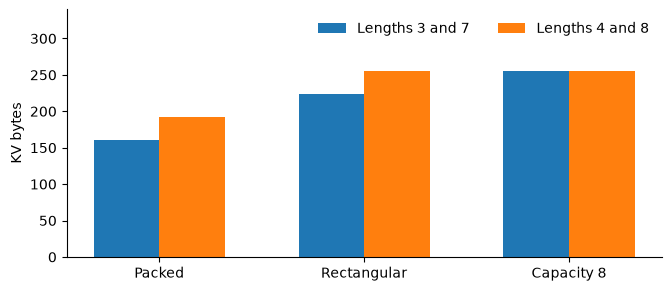

In [6]:
def cache_sizes(lengths,capacity):
    positions=np.array(lengths)
    assert positions.max()<=capacity
    return (positions.sum()*16,len(positions)*positions.max()*16,
            len(positions)*capacity*16)
before=cache_sizes([3,7],8);after=cache_sizes([4,8],8)
assert before==(160,224,256) and after==(192,256,256)
print("Packed / rectangular / capacity-eight:")
print("Lengths 3,7:",before,"Lengths 4,8:",after)
fig,ax=plt.subplots(figsize=(6.6,2.8),layout="constrained")
x=np.arange(3)
ax.bar(x-.16,before,width=.32,label="Lengths 3 and 7")
ax.bar(x+.16,after,width=.32,label="Lengths 4 and 8")
ax.set(xticks=x,xticklabels=["Packed","Rectangular","Capacity 8"],
       ylabel="KV bytes",ylim=(0,340))
ax.legend(frameon=False,ncol=2);plt.show()

## 6. Solve a history budget

**Problem.** One sequence has two attention layers with one KV head, key/value widths eight and two-byte scalars, plus 32 FP32 recurrent scalars. Find the largest full-cache prefix under 1,152 bytes and the plateau with a window of eight.

**Solution.** Each position across the two attention layers costs $2(8+8)(2)=64$ bytes. The recurrent state needs $32(4)=128$ bytes. Solve $64n+128\le1152$, giving $n\le16$. At 16 the payload is exactly 1,152; at 17 it is 1,216 and no longer fits. With actual eviction to a window of eight, the history is $64\min(n,8)+128$, which plateaus at 640 bytes. This budget covers history only, not weights, workspaces, or allocator overhead.

Largest full prefix: 16 Window plateau: 640 bytes


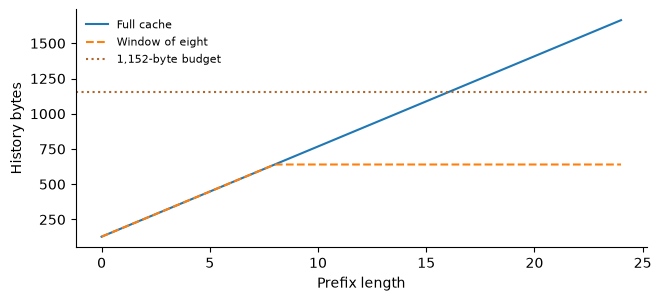

In [7]:
budget=1152;state=32*4;per_position=2*(8+8)*2
limit=(budget-state)//per_position
assert limit==16 and per_position*(limit+1)+state>budget
n=np.arange(0,25);full=per_position*n+state
window=per_position*np.minimum(n,8)+state
assert window.max()==640
print("Largest full prefix:",limit,"Window plateau:",window.max(),"bytes")
fig,ax=plt.subplots(figsize=(6.5,2.9),layout="constrained")
ax.plot(n,full,label="Full cache")
ax.plot(n,window,"--",label="Window of eight")
ax.axhline(budget,color="#ad672d",linestyle=":",label="1,152-byte budget")
ax.set(xlabel="Prefix length",ylabel="History bytes")
ax.legend(frameon=False,fontsize=8);plt.show()

## 7. Count live overlap

**Problem.** Persistent arrays use 8 MiB, saved activations 3, a forward workspace 5, and a backward workspace 4. The four phases are forward workspace live, forward workspace freed, backward workspace live, and saved tensors freed. Reproduce totals and add a 2 MiB copy through phases 1-3. What if it is a view?

**Solution.** The totals are $8+3+5=16$, $8+3=11$, $8+3+4=15$, and 8 MiB. Peak payload is 16 MiB; summing all allocations would incorrectly give 20 because the workspaces do not coexist. A real 2 MiB copy in the first three phases gives totals $(18,13,17,8)$ and peak 18. A view sharing existing storage adds no second 2 MiB payload, so the tensor-payload peak stays 16. Small view metadata and allocator reservations belong to separate accounting.

In [8]:
persistent=np.array([8,8,8,8]);saved=np.array([3,3,3,0])
forward=np.array([5,0,0,0]);backward=np.array([0,0,4,0])
live=persistent+saved+forward+backward
with_copy=live+np.array([2,2,2,0])
np.testing.assert_array_equal(live,[16,11,15,8])
assert live.max()==16 and with_copy.max()==18
print("Original live MiB:",live,"Peak:",live.max())
print("With materialized copy:",with_copy,"Peak:",with_copy.max())
print("With a shared-storage view: payload peak remains 16 MiB.")

Original live MiB: [16 11 15  8] Peak: 16
With materialized copy: [18 13 17  8] Peak: 18
With a shared-storage view: payload peak remains 16 MiB.


## 8. Audit a throughput claim

**Problem.** Four concurrent requests start at 0 and each emit tokens at 90, 115, 140, and 165 ms. Find TTFT, inter-token latency, aggregate decode throughput, and aggregate complete-request output throughput. Audit $16/0.075$ and a claim that halving KV bytes halves time.

**Solution.** Each request has TTFT 90 ms and subsequent intervals 25 ms. After the first emission, the batch generates $4(3)=12$ tokens in 75 ms, giving 160 tokens/s. Across the complete interval, it generates $4(4)=16$ in 165 ms, giving about 96.97 tokens/s. The claim $16/0.075\approx213.33$ includes the first tokens in its numerator while excluding their elapsed time. A single request has 40 tokens/s steady cadence here, which is distinct from batch throughput. KV payload does not determine total latency: projections, attention reads, scheduling, communication, and other work must also be measured.

In [9]:
emissions=np.array([90.,115.,140.,165.]);batch=4
intervals=np.diff(emissions)
decode=batch*(len(emissions)-1)/((emissions[-1]-emissions[0])/1000)
complete=batch*len(emissions)/(emissions[-1]/1000)
np.testing.assert_array_equal(intervals,[25,25,25])
assert decode==160
np.testing.assert_allclose(complete,96.9696969697)
print("TTFT:",emissions[0],"ms; intervals:",intervals,"ms")
print("Aggregate decode:",decode,"tokens/s")
print("Aggregate complete-request:",complete,"tokens/s")
print("Inconsistent 16/0.075:",16/.075,"tokens/s")

TTFT: 90.0 ms; intervals: [25. 25. 25.] ms
Aggregate decode: 160.0 tokens/s
Aggregate complete-request: 96.96969696969697 tokens/s
Inconsistent 16/0.075: 213.33333333333334 tokens/s
